<a href="https://colab.research.google.com/github/NadaAmalia/analisis-deret-waktu-tolak-hb/blob/main/Analisis_Deret_Waktu_kelas_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mengimpor library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:.2f}'.format)
df = pd.read_csv('data_tolak_hb.csv')
df.head()

,TglPeriksa,Jumlah_Pendonor
0,2026-01-01,77
1,2026-01-02,52
2,2026-01-03,31
3,2026-01-04,33
4,2026-01-05,30


In [ ]:
print("Ukuran Dataset:", df.shape)
df.info()

print("\nNama Kolom:")
print(df.columns.tolist())

Ukuran Dataset: (243, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   TglPeriksa       243 non-null    object
 1   Jumlah_Pendonor  243 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.9+ KB

Nama Kolom:
['TglPeriksa', 'Jumlah_Pendonor']


In [ ]:
df['TglPeriksa'] = pd.to_datetime(df['TglPeriksa'])

print(df.dtypes)

df = df.sort_values(by='TglPeriksa')
df = df.reset_index(drop=True)
df.head(10)

TglPeriksa         datetime64[ns]
Jumlah_Pendonor             int64
dtype: object


,TglPeriksa,Jumlah_Pendonor
0,2026-01-01,77
1,2026-01-02,52
2,2026-01-03,31
3,2026-01-04,33
4,2026-01-05,30
5,2026-01-06,61
6,2026-01-07,37
7,2026-01-08,47
8,2026-01-09,47
9,2026-01-10,66


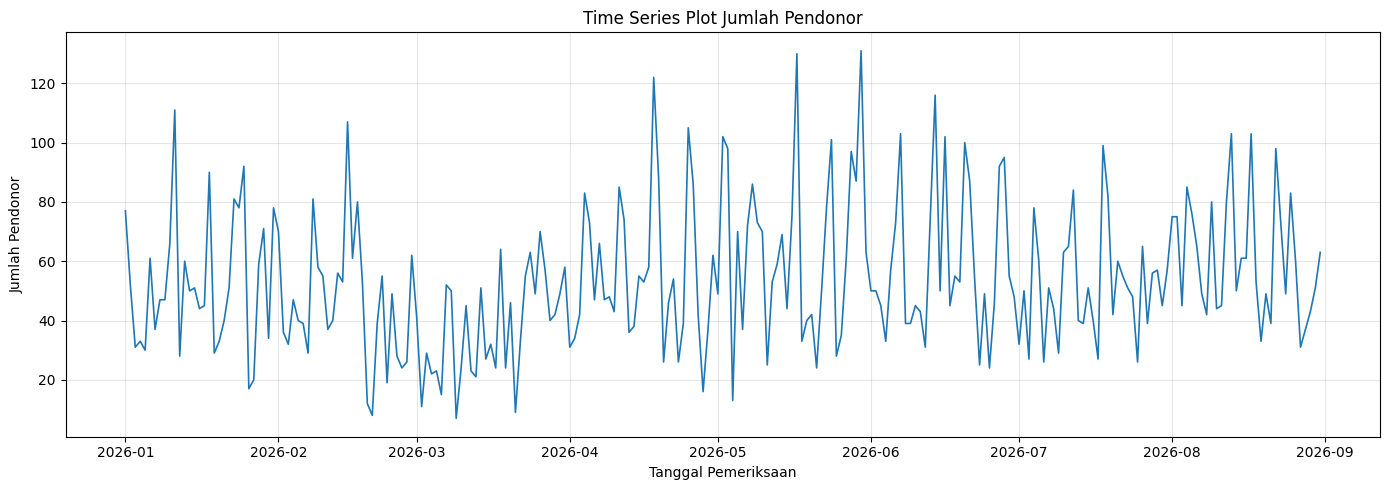

In [ ]:
# Membuat visualisasi time series
plt.figure(figsize=(14, 5))

plt.plot(
    df['TglPeriksa'],
    df['Jumlah_Pendonor'],
    linewidth=1.2)

plt.title('Time Series Plot Jumlah Pendonor')
plt.xlabel('Tanggal Pemeriksaan')
plt.ylabel('Jumlah Pendonor')

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

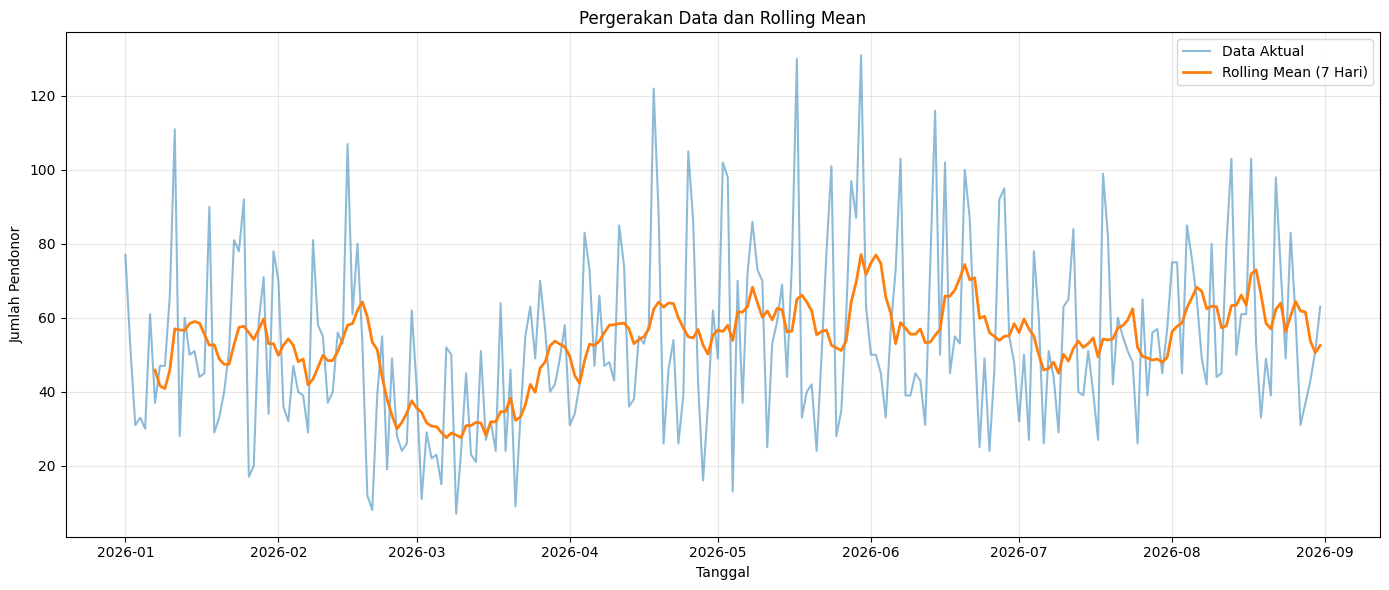

In [ ]:
# Menghitung rolling mean dan standard deviation
df['Rolling_Mean'] = (
    df['Jumlah_Pendonor'].rolling(window=7).mean())

df['Rolling_Std'] = (
    df['Jumlah_Pendonor'].rolling(window=7).std())

# Membuat visualisasi
plt.figure(figsize=(14, 6))

plt.plot(
    df['TglPeriksa'],
    df['Jumlah_Pendonor'],
    label='Data Aktual',
    alpha=0.5)

plt.plot(
    df['TglPeriksa'],
    df['Rolling_Mean'],
    label='Rolling Mean (7 Hari)',
    linewidth=2
)

plt.title('Pergerakan Data dan Rolling Mean')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Pendonor')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

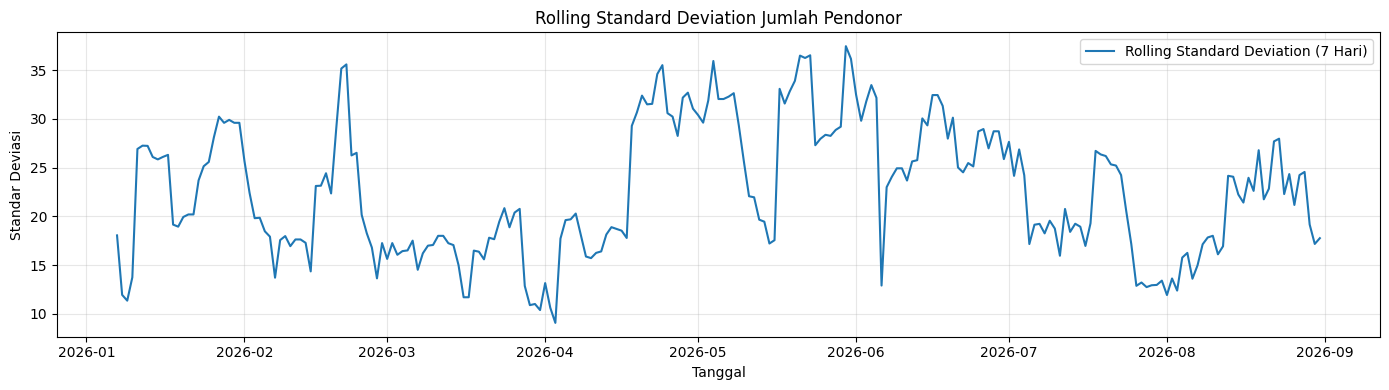

In [ ]:
plt.figure(figsize=(14, 4))

plt.plot(
    df['TglPeriksa'],
    df['Rolling_Std'],
    label='Rolling Standard Deviation (7 Hari)')

plt.title('Rolling Standard Deviation Jumlah Pendonor')
plt.xlabel('Tanggal')
plt.ylabel('Standar Deviasi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ADF Statistic: -1.8997722789968998
P-value: 0.33216824545145107

Critical Values:
1%: -3.4592326027153493
5%: -2.8742454699025872
10%: -2.5735414688888465

Data tidak stasioner


/tmp/ipykernel_1956/856829708.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil_adf = adfuller(data, autolag='AIC')


<Figure size 1200x400 with 0 Axes>

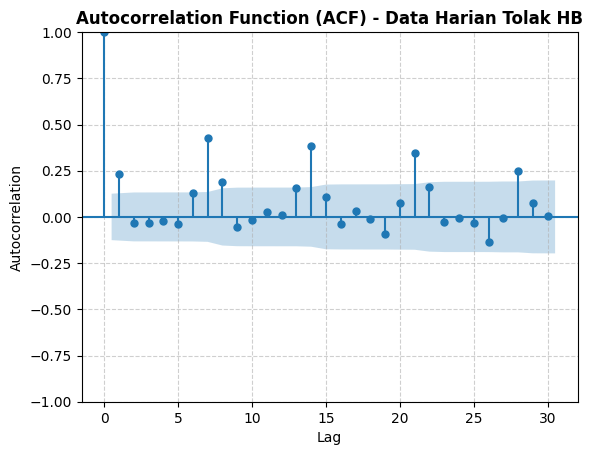

In [ ]:
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Melakukan uji ADF
hasil_adf = adfuller(data, autolag='AIC')

# Menampilkan hasil
print('ADF Statistic:', hasil_adf[0])
print('P-value:', hasil_adf[1])

print('\nCritical Values:')
for key, value in hasil_adf[4].items():
    print(f'{key}: {value}')

if hasil_adf[1] < 0.05:
    print('\nData stasioner')
else:
    print('\nData tidak stasioner')

# Membuat plot ACF (Autocorrelation Function)
plt.figure(figsize=(12, 4))
plot_acf(df["Jumlah_Pendonor"], lags=30, alpha=0.05)

plt.title("Autocorrelation Function (ACF) - Data Harian Tolak HB", fontsize=12, fontweight='bold')
plt.xlabel("Lag", fontsize=10)
plt.ylabel("Autocorrelation", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()